# DAY 1: Exploring data 
#### *Open Tools, Open Sky: Doing LSST Science with Public Rubin Data & LINCC Frameworks, UdeA, Medellín, October 13 2026*

In [1]:
import pandas as pd

#Read the Vera C. Rubin Observatory Observations Submitted to the Minor Planet Center.
#This version has the MPC designation of each object (column mpc_designation), added in add_mpc_designation.ipynb
data = pd.read_parquet('data/obs_sbn_X05_full_mpc_desig.parquet', engine='pyarrow')
data['mag'] = pd.to_numeric(data['mag'], errors='coerce')

In [2]:
# Example: 2025 MD38 is a secondary designation of 2014 HR48, so its orbit is listed under 2014 HR48
data.loc[data['provid'] == '2025 MD38', ['provid', 'permid', 'mpc_designation', 'match_by']].head()

,provid,permid,mpc_designation,match_by
18278,2025 MD38,None,2014 HR48,other_desig
18279,2025 MD38,None,2014 HR48,other_desig
18280,2025 MD38,None,2014 HR48,other_desig
18281,2025 MD38,None,2014 HR48,other_desig
18282,2025 MD38,None,2014 HR48,other_desig


In [3]:
#cheking data columns to see what information we have
data.columns

Index(['id', 'trksub', 'trkid', 'obsid', 'submission_id',
       'submission_block_id', 'obs80', 'status', 'ref', 'healpix', 'permid',
       'provid', 'artsat', 'mode', 'stn', 'trx', 'rcv', 'sys', 'ctr', 'pos1',
       'pos2', 'pos3', 'poscov11', 'poscov12', 'poscov13', 'poscov22',
       'poscov23', 'poscov33', 'prog', 'obstime', 'ra', 'dec', 'rastar',
       'decstar', 'obscenter', 'deltara', 'deltadec', 'dist', 'pa', 'rmsra',
       'rmsdec', 'rmsdist', 'rmspa', 'rmscorr', 'delay', 'rmsdelay', 'doppler',
       'rmsdoppler', 'astcat', 'mag', 'rmsmag', 'band', 'photcat', 'photap',
       'nucmag', 'logsnr', 'seeing', 'exp', 'rmsfit', 'com', 'frq', 'disc',
       'subfrm', 'subfmt', 'prectime', 'precra', 'precdec', 'unctime', 'notes',
       'remarks', 'deprecated', 'localuse', 'nstars', 'prev_desig', 'prev_ref',
       'rmstime', 'created_at', 'updated_at', 'trkmpc', 'orbit_id',
       'designation_asterisk', 'shapeocc', 'obssubid', 'replacesobsid',
       'group_id', 'vel1', 'fltr'

## MPC designation of each detection

We want the orbital elements of the objects observed by Vera Rubin. Each detection is identified by its `permid`
(number) and/or `provid` (provisional designation), but the same object can appear in the MPC orbit catalogue under
another designation (e.g. `2025 MD38` is listed as `2014 HR48`). The cross match was already done in
`add_mpc_designation.ipynb`, which stored the MPCORB `designation` of each detection in `mpc_designation`
and how it was matched in `match_by`:
- `permid`: by number;
- `provid`: by the main provisional designation in MPCORB;
- `other_desig`: by one of the other (secondary) designations of the object;
- null: no designation (comets, which are not in MPCORB, or `permid` and `provid` both null).

In [4]:
has_desig = data['mpc_designation'].notna()
print(f"Detections with an MPC designation: {has_desig.sum():,} of {len(data):,} ({100 * has_desig.mean():.2f}%)")

summary = data['match_by'].value_counts(dropna=False).rename('rows').to_frame()
summary['percent'] = (100 * summary['rows'] / len(data)).round(2)
summary

Detections with an MPC designation: 7,954,397 of 8,078,546 (98.46%)


,rows,percent
match_by,,
permid,4787748,59.26
provid,3147917,38.97
None,124149,1.54
other_desig,18732,0.23


## MPCORB: orbits of all known minor planets

`data/mpcorb_extended.dat.gz` is the Minor Planet Center's orbit catalogue: one fixed-width line per object
with its orbital elements (a, e, i, ...), absolute magnitude H, and orbit-quality information.
The extended version adds the time of perihelion. We only read the columns needed for the orbits;
`designation` is the key that matches `mpc_designation` in the observations.

In [5]:
import gzip
import numpy as np

path = 'data/mpcorb_extended.dat.gz'

# Fixed-width columns of MPCORB (https://www.minorplanetcenter.org/iau/info/MPOrbitFormat.html),
# as 0-based [start, end) slices, plus the "extended" time of perihelion after column 202
colspecs = {
    'H':             (8, 13),     # absolute magnitude
    'G':             (14, 19),    # slope parameter
    'epoch_packed':  (20, 25),    # epoch of the elements, packed (e.g. K2669)
    'M':             (26, 35),    # mean anomaly [deg]
    'peri':          (37, 46),    # argument of perihelion [deg]
    'node':          (48, 57),    # longitude of ascending node [deg]
    'incl':          (59, 68),    # inclination [deg]
    'e':             (70, 79),    # eccentricity
    'a':             (92, 103),   # semimajor axis [AU]
    'U':             (105, 106),  # uncertainty parameter (0 = best, 9 = worst)
    'n_obs':         (117, 122),  # number of observations
    'n_opp':         (123, 126),  # number of oppositions
    'arc':           (127, 136),  # 'yyyy-yyyy' or 'nnnn days'
    'designation':   (166, 194),  # readable designation, e.g. '(1) Ceres' or '2021 AQ'
    'tp_jd':         (203, 216),  # extended: time of perihelion [JD]
}

# The data start after the header's line of dashes
with gzip.open(path, 'rt') as f:
    for i, line in enumerate(f):
        if line.startswith('-----'):
            header_lines = i + 1
            break

mpcorb = pd.read_fwf(path, compression='gzip', skiprows=header_lines, header=None,
                     colspecs=list(colspecs.values()), names=list(colspecs.keys()),
                     dtype={'U': str},
                     skip_blank_lines=True, dtype_backend='pyarrow')   # pyarrow types use much less memory

The epoch in the MPC is encoded. We create a function to decoded it 

In [6]:
def unpack_epoch(s):
    """Packed MPC date (e.g. 'K2669' = 2026-06-09) -> 'YYYY-MM-DD'."""
    digit = lambda c: int(c) if c.isdigit() else ord(c) - ord('A') + 10
    year = {'I': 1800, 'J': 1900, 'K': 2000}[s[0]] + int(s[1:3])
    return f'{year}-{digit(s[3]):02d}-{digit(s[4]):02d}'


epochs = mpcorb['epoch_packed'].map(unpack_epoch)
mpcorb['epoch_mjd'] = (pd.to_datetime(epochs) - pd.Timestamp('1858-11-17')).dt.days.astype(float)

# Perihelion and aphelion distances [AU]
mpcorb['q'] = mpcorb['a'] * (1 - mpcorb['e'])
mpcorb['Q'] = mpcorb['a'] * (1 + mpcorb['e'])

In [7]:
print(f'{len(mpcorb):,} objects')
mpcorb.head()

1,573,538 objects


,H,G,epoch_packed,M,peri,node,incl,e,a,U,n_obs,n_opp,arc,designation,tp_jd,epoch_mjd,q,Q
0,3.34,0.15,K2669,274.41935,73.2942,80.24863,10.58803,0.079692,2.765553,0,7376,127,1801-2026,(1) Ceres,2461599.84154,61200.0,2.545159,2.985946
1,4.12,0.15,K2669,254.24963,310.96993,172.88661,34.93279,0.2307,2.769559,0,9072,124,1804-2026,(2) Pallas,2461695.03127,61200.0,2.130621,3.408497
2,5.21,0.15,K2669,262.73228,247.89506,169.81163,12.98659,0.2557,2.67099,0,7691,119,1804-2026,(3) Juno,2461631.2974,61200.0,1.988018,3.353961
3,3.25,0.15,K2669,81.19019,151.46856,103.70135,7.14393,0.090204,2.361366,0,7610,112,1821-2025,(4) Vesta,2460901.58719,61200.0,2.148362,2.57437
4,6.95,0.15,K2669,181.4782,359.37562,141.44723,5.35968,0.187574,2.576808,0,3658,91,1845-2026,(5) Astraea,2461949.72149,61200.0,2.093466,3.06015


## Add the MPC orbit to each observation

Since every detection already has its MPC `designation` (column `mpc_designation`), the orbits are added with a
simple join on the designation. The orbital elements are added as `mpc_*` columns,
and `mpc_row` is the row of the object in MPCORB.

In [8]:
# Simple join on the MPC designation (unique in MPCORB, so each detection gets at most one orbit).
# Detections without a designation (comets, or permid and provid both null) stay without orbit.
elements = ['designation', 'a', 'e', 'incl', 'node', 'peri', 'M', 'epoch_mjd', 'q', 'Q',
            'H', 'G', 'U', 'n_obs', 'n_opp', 'arc', 'tp_jd']
mpc = mpcorb[elements].reset_index(drop=True)
mpc['row'] = pd.Series(mpc.index, dtype='Int64')
mpc = mpc.add_prefix('mpc_')          # prefixed mpc_ so they don't clash with the observation columns

# Join only the key column and copy the result back: merging the whole 8M-row table would duplicate it in memory
# (a left merge keeps the row order)
orbits = data[['mpc_designation']].merge(mpc, on='mpc_designation', how='left', validate='many_to_one')
for col in orbits.columns.drop('mpc_designation'):
    data[col] = orbits[col].array

How many detections and objects got an orbit:

In [9]:
obj = data['permid'].fillna(data['provid'])          # object identifier: number if any, else provisional designation
has_orbit = data['mpc_row'].notna()

print(f"Detections with an MPC orbit: {has_orbit.sum():,} of {len(data):,} ({100 * has_orbit.mean():.2f}%)")
print(f"Objects with an MPC orbit:    {data.loc[has_orbit, 'mpc_row'].nunique():,} of {obj.nunique():,} identified objects")
print(f"Objects without an orbit:     {obj[obj.notna() & ~has_orbit].nunique():,} (comets are not in MPCORB)")
print(f"Unidentified detections (permid and provid null): {obj.isna().sum():,}")
data['match_by'].value_counts(dropna=False)

Detections with an MPC orbit: 7,954,397 of 8,078,546 (98.46%)
Objects with an MPC orbit:    295,901 of 301,088 identified objects
Objects without an orbit:     2,436 (comets are not in MPCORB)
Unidentified detections (permid and provid null): 63,825


match_by
permid         4787748
provid         3147917
None            124149
other_desig      18732
Name: count, dtype: int64

We select only the columns we need later to perform the propagation and H calculation 

In [10]:
obs_orbit_elements=data[['obstime', 'permid', 'provid', 'mag', 'rmsmag', 'mpc_row', 'match_by', 'mpc_designation', 'mpc_a', 'mpc_e', 'mpc_incl',
                'mpc_node', 'mpc_peri', 'mpc_M', 'mpc_q', 'mpc_epoch_mjd', 'mpc_H', 'mpc_tp_jd']]
obs_orbit_elements.head()

,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,mpc_a,mpc_e,mpc_incl,mpc_node,mpc_peri,mpc_M,mpc_q,mpc_epoch_mjd,mpc_H,mpc_tp_jd
0,2025-04-28 07:22:39.331,None,None,23.278,0.137,<NA>,None,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>
1,2025-04-28 06:33:03.818,None,None,22.876,0.123,<NA>,None,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>
2,2025-04-28 06:57:29.266,None,None,23.469,0.157,<NA>,None,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>
3,2025-04-28 06:37:18.266,None,None,23.198,0.166,<NA>,None,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>
4,2025-04-28 06:21:30.925,None,None,22.929,0.168,<NA>,None,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>


In [11]:
# Keep only detections matched to an MPCORB orbit
obs_orbit_elements_clean = obs_orbit_elements.dropna(subset=['mpc_row'])
print(f"Kept {len(obs_orbit_elements_clean):,} of {len(obs_orbit_elements):,} rows")
obs_orbit_elements_clean.head()

Kept 7,954,397 of 8,078,546 rows


,obstime,permid,provid,mag,rmsmag,mpc_row,match_by,mpc_designation,mpc_a,mpc_e,mpc_incl,mpc_node,mpc_peri,mpc_M,mpc_q,mpc_epoch_mjd,mpc_H,mpc_tp_jd
552,2025-05-02 00:42:01.796,None,2025 MD8,23.096,0.124,1487851,provid,2025 MD8,2.814204,0.119711,4.36485,115.86923,328.92434,182.48178,2.477313,61200.0,18.65,2462050.80033
553,2025-05-02 00:39:54.996,None,2025 MD8,22.927,0.127,1487851,provid,2025 MD8,2.814204,0.119711,4.36485,115.86923,328.92434,182.48178,2.477313,61200.0,18.65,2462050.80033
554,2025-05-02 01:01:01.387,None,2025 MD8,23.055,0.105,1487851,provid,2025 MD8,2.814204,0.119711,4.36485,115.86923,328.92434,182.48178,2.477313,61200.0,18.65,2462050.80033
555,2025-05-02 01:03:10.218,None,2025 MD8,23.059,0.129,1487851,provid,2025 MD8,2.814204,0.119711,4.36485,115.86923,328.92434,182.48178,2.477313,61200.0,18.65,2462050.80033
556,2025-05-02 01:29:18.645,None,2025 MD8,22.911,0.072,1487851,provid,2025 MD8,2.814204,0.119711,4.36485,115.86923,328.92434,182.48178,2.477313,61200.0,18.65,2462050.80033


Some plots to see the distribution of orbital elements...

In [12]:
data_orbs = obs_orbit_elements_clean

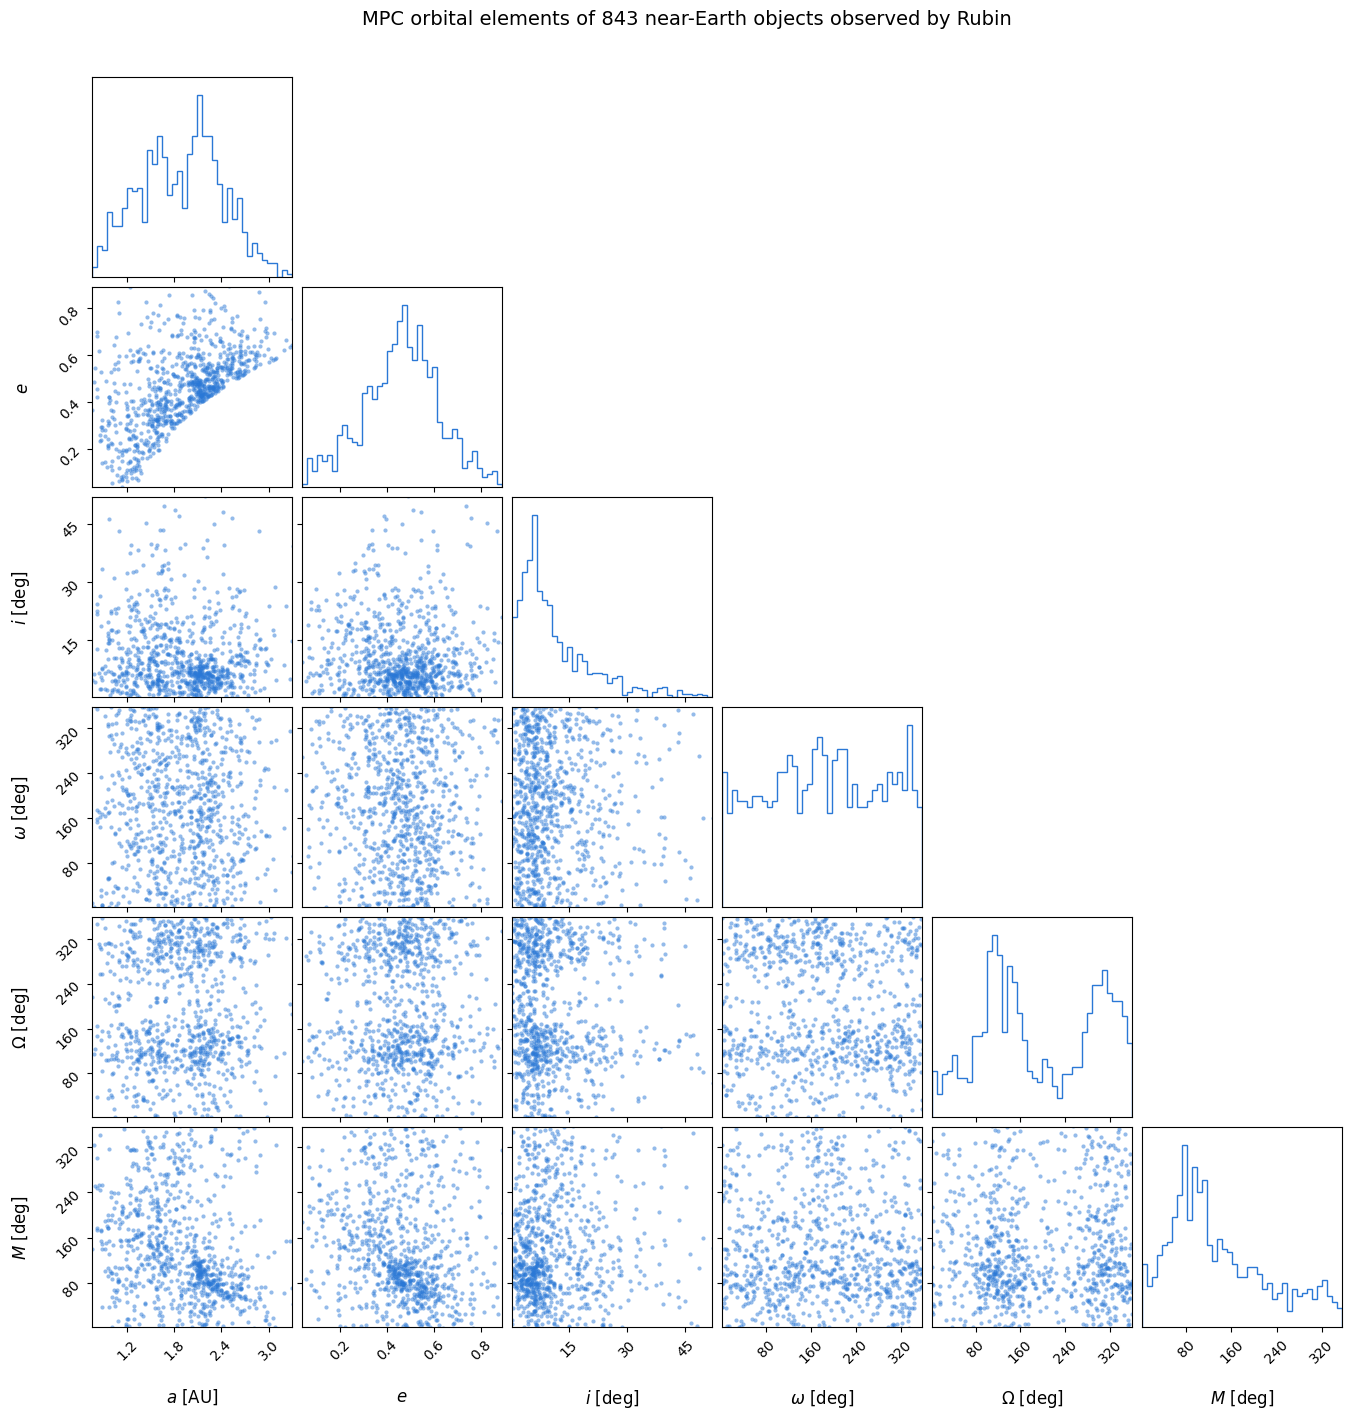

In [13]:
import corner
import matplotlib.pyplot as plt
# Corner plot only for near-Earth objects (NEOs): perihelion distance q < 1.3 AU
neo = data_orbs[data_orbs['mpc_q'] < 1.3].drop_duplicates('mpc_row')   # one row per object
neo_samples = neo[['mpc_a', 'mpc_e', 'mpc_incl', 'mpc_peri', 'mpc_node', 'mpc_M']].astype(float).to_numpy()

neo_labels = [r'$a$ [AU]', r'$e$', r'$i$ [deg]', r'$\omega$ [deg]', r'$\Omega$ [deg]', r'$M$ [deg]']
fig = corner.corner(neo_samples, labels=neo_labels, bins=40, range=[0.995] * 6,   # each axis: central 99.5%
                    color='#2a78d6', label_kwargs=dict(fontsize=12),
                    # scatter: one point per NEO, no density contours
                    plot_datapoints=True, plot_density=False, plot_contours=False,
                    data_kwargs=dict(alpha=0.5, ms=3))
fig.suptitle(f'MPC orbital elements of {len(neo_samples):,} near-Earth objects observed by Rubin', fontsize=14, y=1.02)

# Save as PNG (bbox_inches='tight' keeps the title, which sits above the axes)
import os
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/neos_corner_plot.png', dpi=200, bbox_inches='tight')
plt.show()

In [14]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Bin with numpy first and plot only the counts: plotting the ~8M raw values would store them all in the notebook
q_counts, q_edges = np.histogram(data_orbs['mpc_q'].astype(float), bins=200)
e_counts, e_edges = np.histogram(data_orbs['mpc_e'].astype(float), bins=200, range=(0, 1))

fig = make_subplots(rows=2, cols=1, vertical_spacing=0.15,
                    subplot_titles=('Perihelion distance', 'Eccentricity'))
fig.add_trace(go.Bar(x=(q_edges[:-1] + q_edges[1:]) / 2, y=q_counts, width=np.diff(q_edges),
                     marker_color='#2a78d6', name='q',
                     hovertemplate='q = %{x:.2f} AU<br>%{y:,} detections<extra></extra>'), row=1, col=1)
fig.add_trace(go.Bar(x=(e_edges[:-1] + e_edges[1:]) / 2, y=e_counts, width=np.diff(e_edges),
                     marker_color='#eb6834', name='e',
                     hovertemplate='e = %{x:.3f}<br>%{y:,} detections<extra></extra>'), row=2, col=1)

fig.update_xaxes(title_text='Perihelion distance q [AU]', row=1, col=1)
fig.update_xaxes(title_text='Eccentricity e (dimensionless)', row=2, col=1)
fig.update_yaxes(type='log', title_text='Number of detections (log scale)')
fig.update_layout(height=750, showlegend=False, bargap=0,
                  title='MPC orbits of the objects observed by Rubin')
fig.show()

## State vector of each orbit (SPICE)

`spy.conics` converts the MPC elements (q, e, i, Ω, ω, M) into a position and velocity. The result is:
- **heliocentric**, in the **ecliptic J2000** frame (the frame of the MPC elements; SPICE calls it `ECLIPJ2000`);
- in **km** and **km/s**, because GM of the Sun from the DE440 kernel is in km³/s²;
- at the **epoch of the elements** (`mpc_epoch_mjd`), given in `epoch_et` as seconds past J2000 TDB.

The kernels are in `kernels/`, downloaded from https://naif.jpl.nasa.gov/pub/naif/generic_kernels/.

In [15]:
import spiceypy as spy

spy.furnsh('kernels/naif0012.tls')    # leap seconds: needed to convert dates to ephemeris time (ET)
spy.furnsh('kernels/gm_de440.tpc')    # GM of the Sun and planets from the DE440 ephemeris
mu_sun = spy.bodvrd('SUN', 'GM', 1)[1][0]   # [km^3/s^2]
AU_KM = 149597870.7                         # IAU 2012 astronomical unit [km]


def trasformation_E_to_X(q: float, e: float, i: float, Omega: float, w: float, M: float, mu: float) -> tuple[float, float, float, float, float, float]:

    state_vec = spy.conics([q, e, i, Omega, w, M]+[0, mu], 0)
    x = state_vec[0]
    y = state_vec[1]
    z = state_vec[2]
    vx = state_vec[3]
    vy = state_vec[4]
    vz = state_vec[5]

    return x, y, z, vx, vy, vz


# One state vector per orbit: many detections share the same orbit (same mpc_row)
orbits = data_orbs.drop_duplicates('mpc_row').set_index('mpc_row')

# conics wants q in the same length unit as mu (km) and the angles in radians.
# With t0 = 0 and et = 0 the state is at the epoch of the elements (mpc_epoch_mjd).
q_km = orbits['mpc_q'].to_numpy(dtype=float) * AU_KM
e = orbits['mpc_e'].to_numpy(dtype=float)
i, Omega, w, M = (np.radians(orbits[c].to_numpy(dtype=float))
                  for c in ['mpc_incl', 'mpc_node', 'mpc_peri', 'mpc_M'])

states = pd.DataFrame([trasformation_E_to_X(*el, mu_sun) for el in zip(q_km, e, i, Omega, w, M)],
                      index=orbits.index, columns=['x', 'y', 'z', 'vx', 'vy', 'vz'])

# Epoch of each state vector as ephemeris time (seconds past J2000 TDB); MPC epochs are TT, within 2 ms of TDB
epoch_et = {mjd: spy.str2et(f'JD {mjd + 2400000.5} TDB') for mjd in orbits['mpc_epoch_mjd'].unique()}
states['epoch_et'] = orbits['mpc_epoch_mjd'].map(epoch_et)

# Add the state vector to every detection
data_clean = data_orbs.join(states, on='mpc_row')

In [16]:
data_clean.columns

Index(['obstime', 'permid', 'provid', 'mag', 'rmsmag', 'mpc_row', 'match_by',
       'mpc_designation', 'mpc_a', 'mpc_e', 'mpc_incl', 'mpc_node', 'mpc_peri',
       'mpc_M', 'mpc_q', 'mpc_epoch_mjd', 'mpc_H', 'mpc_tp_jd', 'x', 'y', 'z',
       'vx', 'vy', 'vz', 'epoch_et'],
      dtype='object')

In [ ]:
out = 'data/obs_elements_state.parquet'
data_clean.to_parquet(out, engine='pyarrow', index=False)
print(f'Saved {len(data_clean):,} rows x {data_clean.shape[1]} columns to {out}')

Saved 7,954,397 rows x 25 columns to data/obs_elements_state.parquet


: 

## Orbit viewer of an asteroid

Plots the asteroid set in `TARGET` (number or provisional designation; `None` picks a random one) from `data_clean` and animates it with the inner planets and Jupiter, one day per frame,
starting at its first Rubin detection. The asteroid moves on its MPC orbit (two-body: the mean anomaly advances
with the mean motion from the epoch of the elements); the planets use Standish's J2000 elements and rates.
Both are heliocentric ecliptic J2000. With `TARGET = None`, run the cell again to get another asteroid.

In [37]:
"""
3D "solar system + asteroid" orbit viewer with Play/Pause + a slider that steps 1 day at a time,
for an asteroid observed by Rubin (chosen with TARGET, or random), using its real MPC orbital elements from data_clean.
"""
import datetime as dt
import numpy as np
import plotly.graph_objects as go

# ------------------------------------------- choose the asteroid (one row per orbit)
TARGET = '347940'     # number (permid) or provisional designation (provid); None = pick a random asteroid

orbs_unique = data_clean.drop_duplicates('mpc_row')
if TARGET is None:
    ast_row = orbs_unique.sample(1).iloc[0]                          # add random_state=... to repeat a pick
else:
    desig = orbs_unique['mpc_designation'].astype(str)
    found = orbs_unique[desig.str.startswith(f'({TARGET})') | (desig == TARGET)]   # '(347940) ...' or '2025 AB1'
    if found.empty:
        raise ValueError(f'{TARGET} is not in data_clean (no Rubin detection with an MPC orbit)')
    ast_row = found.iloc[0]
AST = dict(name=str(ast_row['mpc_designation']),
           a=float(ast_row['mpc_a']), e=float(ast_row['mpc_e']), i=float(ast_row['mpc_incl']),
           Om=float(ast_row['mpc_node']), w=float(ast_row['mpc_peri']),
           M_epoch=float(ast_row['mpc_M']),                    # mean anomaly at the epoch of the elements
           jd_epoch=float(ast_row['mpc_epoch_mjd']) + 2400000.5,
           color="#ffffff")
print(f"{AST['name']}: a = {AST['a']:.3f} au, e = {AST['e']:.3f}, i = {AST['i']:.2f} deg")

# ---------------------------------------------------------------- settings
# Start at the asteroid's first Rubin detection
first_obs = data.loc[data_clean.index[data_clean['mpc_row'] == ast_row['mpc_row']], 'obstime'].min()
START = pd.Timestamp(first_obs).to_pydatetime().replace(tzinfo=dt.timezone.utc)
Q = AST['a'] * (1 + AST['e'])                                  # aphelion distance [au]
period_days = 365.25 * AST['a'] ** 1.5
N_DAYS = int(min(max(120, period_days), 4 * 365))             # one orbit, between 120 days and 4 years
LIM = max(1.75, 1.1 * Q)                                      # axis half-range (au): fit the whole orbit

# ------------------------------------------- planets (Standish, J2000 + rates/century)
# a, e, I, L, long_peri, long_node  (deg / au)  and their per-century rates
PLANETS = {
    "Mercury": dict(el=[0.38709927, 0.20563593, 7.00497902, 252.25032350, 77.45779628, 48.33076593],
                    rt=[0.00000037, 0.00001906, -0.00594749, 149472.67411175, 0.16047689, -0.12534081],
                    color="#ff00c8"),
    "Venus":   dict(el=[0.72333566, 0.00677672, 3.39467605, 181.97909950, 131.60246718, 76.67984255],
                    rt=[0.00000390, -0.00004107, -0.00078890, 58517.81538729, 0.00268329, -0.27769418],
                    color="#a366e0"),
    "Earth":   dict(el=[1.00000261, 0.01671123, -0.00001531, 100.46457166, 102.93768193, 0.0],
                    rt=[0.00000562, -0.00004392, -0.01294668, 35999.37244981, 0.32327364, 0.0],
                    color="#1ec8ff"),
    "Mars":    dict(el=[1.52371034, 0.09339410, 1.84969142, -4.55343205, -23.94362959, 49.55953891],
                    rt=[0.00001847, 0.00007882, -0.00813131, 19140.30268499, 0.44441088, -0.29257343],
                    color="#ff3c14"),
    "Jupiter": dict(el=[5.20288700, 0.04838624, 1.30439695, 34.39644051, 14.72847983, 100.47390909],
                    rt=[-0.00011607, -0.00013253, -0.00183714, 3034.74612775, 0.21252668, 0.20469106],
                    color="#e0a050"),
}


# ---------------------------------------------------------------- helpers
def kepler_E(M, e, it=30):
    M = np.radians(M) % (2 * np.pi)
    E = M + e * np.sin(M)
    for _ in range(it):
        E = E - (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
    return E


def xyz_from_E(a, e, i, Om, w, E):
    """Heliocentric ecliptic coords (au) from eccentric anomaly E (rad)."""
    i, Om, w = np.radians([i, Om, w])
    xp = a * (np.cos(E) - e)
    yp = a * np.sqrt(1 - e**2) * np.sin(E)
    cw, sw, cO, sO, ci, si = np.cos(w), np.sin(w), np.cos(Om), np.sin(Om), np.cos(i), np.sin(i)
    x = (cw * cO - sw * sO * ci) * xp + (-sw * cO - cw * sO * ci) * yp
    y = (cw * sO + sw * cO * ci) * xp + (-sw * sO + cw * cO * ci) * yp
    z = (sw * si) * xp + (cw * si) * yp
    return np.array([x, y, z])


def planet_elements(p, T):
    a, e, I, L, wbar, Om = (np.array(p["el"]) + np.array(p["rt"]) * T)
    return a, e, I, Om, wbar - Om, L - wbar          # a, e, i, Om, w, M


def planet_pos(p, T):
    a, e, I, Om, w, M = planet_elements(p, T)
    return xyz_from_E(a, e, I, Om, w, kepler_E(M, e))


def planet_orbit(p, T, n=360):
    a, e, I, Om, w, _ = planet_elements(p, T)
    E = np.linspace(0, 2 * np.pi, n)
    return xyz_from_E(a, e, I, Om, w, E)


def jd(t):
    return 2440587.5 + t.timestamp() / 86400.0


def cent(t):
    return (jd(t) - 2451545.0) / 36525.0


# asteroid: real position from the MPC elements (two-body), M advanced with the mean motion n
n_ast = 0.9856076686 / AST["a"] ** 1.5               # deg/day


def ast_pos(t):
    M = AST["M_epoch"] + n_ast * (jd(t) - AST["jd_epoch"])
    return xyz_from_E(AST["a"], AST["e"], AST["i"], AST["Om"], AST["w"], kepler_E(M, AST["e"]))


T0 = cent(START)

# ---------------------------------------------------------------- static traces
traces = []

# ecliptic grid (z = 0)
g = np.linspace(-LIM, LIM, 21)
gx, gy, gz = [], [], []
for v in g:
    gx += [-LIM, LIM, None]; gy += [v, v, None]; gz += [0, 0, None]
    gx += [v, v, None];      gy += [-LIM, LIM, None]; gz += [0, 0, None]
traces.append(go.Scatter3d(x=gx, y=gy, z=gz, mode="lines",
                           line=dict(color="rgba(150,150,150,0.35)", width=1),
                           hoverinfo="skip", showlegend=False))

# asteroid orbit + vertical "stalks" down to the ecliptic
E = np.linspace(0, 2 * np.pi, 361)
ax_, ay_, az_ = xyz_from_E(AST["a"], AST["e"], AST["i"], AST["Om"], AST["w"], E)
ZLIM = max(0.6, 1.3 * np.abs(az_).max())             # z half-range: fit the inclined orbit

# axes through the Sun (yellow)
for ax in ([(-LIM, LIM), (0, 0), (0, 0)], [(0, 0), (-LIM, LIM), (0, 0)], [(0, 0), (0, 0), (-ZLIM, ZLIM)]):
    traces.append(go.Scatter3d(x=ax[0], y=ax[1], z=ax[2], mode="lines",
                               line=dict(color="gold", width=2), hoverinfo="skip", showlegend=False))

# planet orbits
for name, p in PLANETS.items():
    x, y, z = planet_orbit(p, T0)
    traces.append(go.Scatter3d(x=x, y=y, z=z, mode="lines", name=name,
                               line=dict(color=p["color"], width=4), hoverinfo="skip", showlegend=False))

traces.append(go.Scatter3d(x=ax_, y=ay_, z=az_, mode="lines",
                           line=dict(color="rgba(220,220,220,0.9)", width=3),
                           hoverinfo="skip", showlegend=False))
sx, sy, sz = [], [], []
for xi, yi, zi in zip(ax_[::2], ay_[::2], az_[::2]):
    sx += [xi, xi, None]; sy += [yi, yi, None]; sz += [zi, 0, None]
traces.append(go.Scatter3d(x=sx, y=sy, z=sz, mode="lines",
                           line=dict(color="rgba(200,200,200,0.55)", width=2),
                           hoverinfo="skip", showlegend=False))


# ---------------------------------------------------------------- dynamic trace (bodies)
def bodies_at(day):
    t = START + dt.timedelta(days=day)
    T = cent(t)
    pts, labels, cols = [np.zeros(3)], ["Sun"], ["#9cff8a"]
    for name, p in PLANETS.items():
        pts.append(planet_pos(p, T)); labels.append(name); cols.append(p["color"])
    pts.append(ast_pos(t)); labels.append(AST["name"]); cols.append("#ffffff")
    pts = np.array(pts)
    earth = pts[labels.index("Earth")]; ast = pts[-1]
    info = (f"{AST['name']}<br>Earth Distance: {np.linalg.norm(ast - earth):.3f} au"
            f"<br>Sun Distance: {np.linalg.norm(ast):.3f} au"
            f"<br>{t:%Y-%m-%d %H:%M} UTC")
    return pts, labels, cols, info


def body_trace(day):
    pts, labels, cols, _ = bodies_at(day)
    return go.Scatter3d(x=pts[:, 0], y=pts[:, 1], z=pts[:, 2], mode="markers+text",
                        text=labels, textposition="bottom center",
                        textfont=dict(color=cols, size=13),
                        marker=dict(size=3.5, color="white"),
                        hovertext=labels, hoverinfo="text", showlegend=False)


def info_annotation(text):
    return dict(text=text, xref="paper", yref="paper", x=0.01, y=0.02, xanchor="left",
                yanchor="bottom", align="left", showarrow=False,
                font=dict(color="white", size=12, family="monospace"))


traces.append(body_trace(0))
dyn_idx = len(traces) - 1

frames = []
for day in range(N_DAYS):
    _, _, _, info = bodies_at(day)
    frames.append(go.Frame(data=[body_trace(day)], traces=[dyn_idx], name=str(day),
                           layout=go.Layout(annotations=[info_annotation(info)])))

# ---------------------------------------------------------------- layout
fig = go.Figure(data=traces, frames=frames)
fig.update_layout(
    paper_bgcolor="black", plot_bgcolor="black",
    margin=dict(l=0, r=0, t=0, b=0), height=720,
    annotations=[info_annotation(bodies_at(0)[3])],
    scene=dict(
        xaxis=dict(visible=False, range=[-LIM, LIM]),
        yaxis=dict(visible=False, range=[-LIM, LIM]),
        zaxis=dict(visible=False, range=[-ZLIM, ZLIM]),
        aspectmode="manual", aspectratio=dict(x=1, y=1, z=ZLIM / LIM),
        bgcolor="black",
        camera=dict(eye=dict(x=0.9, y=-1.7, z=0.95)),
    ),
    updatemenus=[dict(
        type="buttons", direction="left", x=1.0, y=1.0, xanchor="right", yanchor="top",
        bgcolor="white",
        buttons=[
            dict(label="⏵", method="animate",
                 args=[None, dict(frame=dict(duration=80, redraw=True), fromcurrent=True, transition=dict(duration=0))]),
            dict(label="⏸", method="animate",
                 args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")]),
        ])],
    sliders=[dict(
        active=0, x=0.05, len=0.9, y=0.0, currentvalue=dict(prefix="Day +", font=dict(color="white")),
        font=dict(color="white"),
        steps=[dict(method="animate", label=str(d),
                    args=[[str(d)], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
               for d in range(N_DAYS)])],
)
fig.show()

(347940) Jorgezuluaga: a = 3.061 au, e = 0.289, i = 18.91 deg
